# Junior Data Analyst – Defect detection task

### How to run
1. Put this notebook in the main folder, next to `train.csv`, `test.csv` and `images/`.
2. Packages: Anaconda (NumPy 1.x) plus OpenCV: `pip install "opencv-python==4.11.0.86"` (newer OpenCV versions require NumPy 2).
3. Run all cells in order (`Kernel → Restart & Run All`). C3 writes `predictions.csv` to the same folder.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, "test:", test.shape)
display(train.head())


train: (168, 10) test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


records: 168


,count,percent
inspector_label,,
OK (0),112,66.67
Defect (1),56,33.33


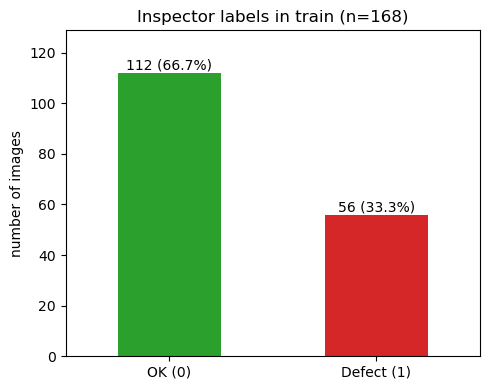

In [3]:
# A1
print("records:", len(train))
counts = train["inspector_label"].value_counts().sort_index()
percents = train["inspector_label"].value_counts(normalize=True).sort_index() * 100
label_dist = pd.DataFrame({"count": counts, "percent": percents.round(2)})
label_dist.index = label_dist.index.map({0: "OK (0)", 1: "Defect (1)"})
display(label_dist)

ax = label_dist["count"].plot(kind="bar", color=["tab:green", "tab:red"], rot=0, figsize=(5, 4))
ax.bar_label(ax.containers[0],
             labels=[f"{c} ({p:.1f}%)" for c, p in zip(label_dist["count"], label_dist["percent"])])
ax.set_title(f"Inspector labels in train (n={len(train)})")
ax.set_xlabel("")
ax.set_ylabel("number of images")
ax.set_ylim(0, label_dist["count"].max() * 1.15)
plt.tight_layout()
plt.show()

,n_images,n_defect,defect_rate
camera,,,
CAM-A,95,30,31.6
CAM-B,73,26,35.6


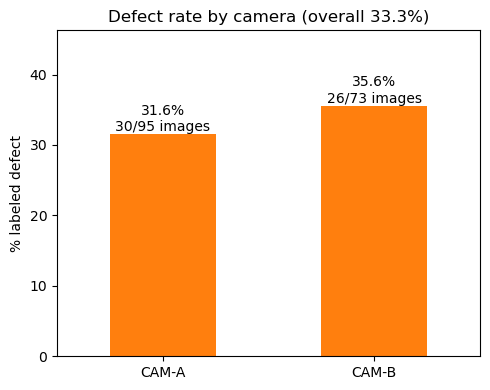

In [4]:
# A2
by_camera = (train.groupby("camera")["inspector_label"]
                  .agg(n_images="count", n_defect="sum", defect_rate="mean"))
by_camera["defect_rate"] = (by_camera["defect_rate"] * 100).round(1)
display(by_camera)

ax = by_camera["defect_rate"].plot(kind="bar", color="tab:orange", rot=0, figsize=(5, 4))
ax.bar_label(ax.containers[0],
             labels=[f"{r}%\n{d}/{n} images" for r, d, n in
                     zip(by_camera["defect_rate"], by_camera["n_defect"], by_camera["n_images"])])
ax.set_title(f"Defect rate by camera (overall {train['inspector_label'].mean()*100:.1f}%)")
ax.set_xlabel("")
ax.set_ylabel("% labeled defect")
ax.set_ylim(0, by_camera["defect_rate"].max() * 1.3)
plt.tight_layout()
plt.show()

exposure_setting,LOW,NORMAL,AUTO
camera,,,
CAM-A,no images,36.7,29.2
CAM-B,37.5,30.0,33.3


CAM-B (n=73): Pearson r = 0.055 (p = 0.65), Fisher p = 0.80


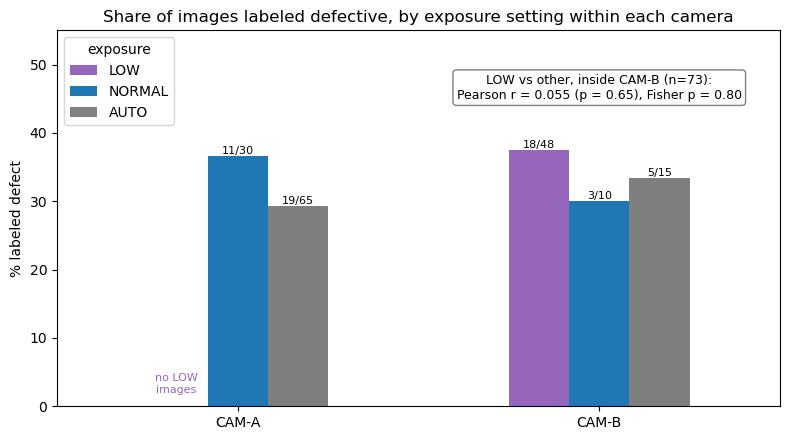

In [5]:
# A3
from scipy.stats import fisher_exact, pearsonr

# 1) numbers for the bars
order = ["LOW", "NORMAL", "AUTO"] #  I know the data and I saw there are no more exposure types provided therefore I hardcoded it here
exp_rate = train.pivot_table(index="camera", columns="exposure_setting",
                             values="inspector_label", aggfunc="mean")[order] * 100
exp_n = train.pivot_table(index="camera", columns="exposure_setting",
                          values="inspector_label", aggfunc="count")[order]
exp_k = train.pivot_table(index="camera", columns="exposure_setting",
                          values="inspector_label", aggfunc="sum")[order]
display(exp_rate.round(1).astype(object).where(exp_rate.notna(), "no images"))

# 2) correlation and test, inside CAM-B only (CAM-A has no LOW images)
train["is_low"] = (train["exposure_setting"] == "LOW").astype(int)
cam_b = train[train["camera"] == "CAM-B"]
r, p_r = pearsonr(cam_b["is_low"], cam_b["inspector_label"])
p_fisher = fisher_exact(pd.crosstab(cam_b["is_low"], cam_b["inspector_label"])).pvalue
print(f"CAM-B (n={len(cam_b)}): Pearson r = {r:.3f} (p = {p_r:.2f}), Fisher p = {p_fisher:.2f}")

# 3) the graph
ax = exp_rate.plot(kind="bar", figsize=(8, 4.5), rot=0, color=["tab:purple", "tab:blue", "tab:gray"])
for bars, exp in zip(ax.containers, order):
    labels = ["" if np.isnan(exp_n.loc[c, exp]) else f"{int(exp_k.loc[c, exp])}/{int(exp_n.loc[c, exp])}"
              for c in exp_rate.index]
    ax.bar_label(bars, labels=labels, fontsize=8)
ax.text(-0.17, 2, "no LOW\nimages", ha="center", fontsize=8, color="tab:purple")
ax.text(1, 45, f"LOW vs other, inside CAM-B (n={len(cam_b)}):\n"
               f"Pearson r = {r:.3f} (p = {p_r:.2f}), Fisher p = {p_fisher:.2f}",
        ha="center", fontsize=9, bbox=dict(boxstyle="round", facecolor="white", edgecolor="gray"))
ax.set_title("Share of images labeled defective, by exposure setting within each camera")
ax.set_xlabel("")
ax.set_ylabel("% labeled defect")
ax.set_ylim(0, 55)
ax.legend(title="exposure", loc="upper left")
plt.tight_layout()
plt.show()

### A3 – Finding and insight

**Finding (what the graph shows):**
The `LOW` exposure setting exists only on camera B (48 of its 73 images); camera A has no LOW images at all. So the effect of low exposure cannot be checked on all the data together: that would mix "low exposure" with "camera B". The fair comparison is within each camera separately. Within each camera, the share of images labeled defective is similar across exposure settings: on CAM-B, 37.5% with LOW exposure (18/48) vs. 30% with NORMAL and 33% with AUTO; on CAM-A, 37% with NORMAL and 29% with AUTO.

**Insight:**
No relationship was found between the exposure setting and the defect label. Within camera B, the Pearson correlation between low exposure and the defect label is close to zero (r = 0.055, p = 0.65; with two binary variables this is the φ coefficient), and Fisher's exact test is not significant either (p = 0.80).
So the exposure setting is probably not correlated with the images being labeled defective.

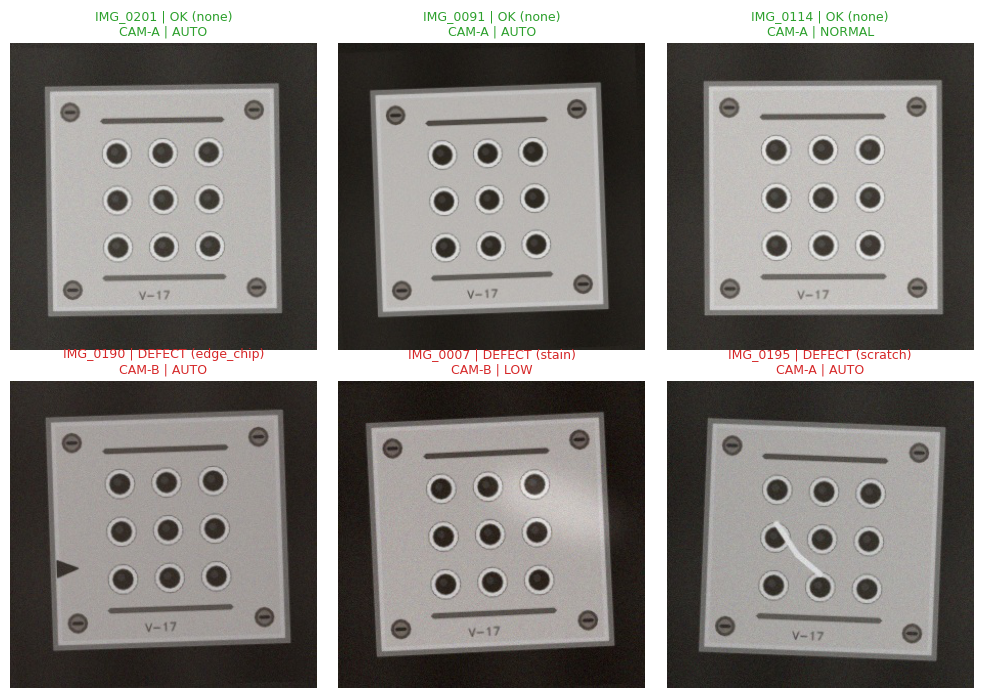

In [7]:
# B1
from PIL import Image

examples = pd.concat([
    train[train["inspector_label"] == 0].sample(n=3, random_state=1),
    train[train["inspector_label"] == 1].sample(n=3, random_state=1),
])

fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (_, row) in zip(axes.flat, examples.iterrows()):
    img = Image.open(DATA_DIR / row["file"])
    ax.imshow(img)
    status = "DEFECT" if row["inspector_label"] == 1 else "OK"
    ax.set_title(f"{row['image_id']} | {status} ({row['inspector_type']})\n{row['camera']} | {row['exposure_setting']}",
                 fontsize=9, color="tab:red" if row["inspector_label"] == 1 else "tab:green")
    ax.axis("off")
plt.tight_layout()
plt.show()

### B1 – Visual difference

All images show the same component (a gray plate with 9 holes, 4 screws and the text "V-17") on a dark background. The defects are small and local, while the rest of the plate looks the same as in the OK images. For example, in IMG_0195 (scratch) there is a bright white diagonal line between the holes, and in IMG_0190 (edge_chip) a dark triangular piece is missing from the left edge of the plate.

Because the defects cover only a small part of the image, a global feature such as mean brightness will probably change very little between OK and defective images.

Note: in IMG_0007 (labeled "stain") I could not see a clear stain. The most visible thing is a diagonal band of light on the right side, which looks more like a lighting reflection than a mark on the part. This may be a labeling issue, since the inspector labels are not necessarily perfect.

In [9]:
%pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [10]:
# B2
import cv2

def extract_features(path):
    """Read an image and return two simple numeric features."""
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) # read in greyscale since the pictures are B&W as observed
    if gray is None:                      # cv2.imread does not raise on a bad path, so I raised to stop before the program collapses on its own
        raise FileNotFoundError(path)

    # sharpness: variance of the Laplacian (higher = more sharp edges, lower = blurrier)
    sharpness = cv2.Laplacian(gray, cv2.CV_64F).var()

    # noise: what a small median filter removes, as % of the 0-255 range
    smooth = cv2.medianBlur(gray, 3)
    residual = gray.astype(np.float64) - smooth.astype(np.float64)
    noise_percent = residual.std() / 255 * 100

    return {"sharpness": float(sharpness), "noise_percentage": float(noise_percent)}

# quick check on one image - REMOVE COMMENT TO RUN
# print(extract_features(DATA_DIR / train.loc[0, "file"]))

In [11]:
# B3 – compute features for all train images

feats = train["file"].apply(lambda f: pd.Series(extract_features(DATA_DIR / f)))
train = pd.concat([train, feats], axis=1)
display(train[["sharpness", "noise_percentage"]].describe().round(2))

,sharpness,noise_percentage
count,168.00,168.00
mean,468.01,1.53
std,175.17,0.38
min,8.20,0.16
25%,333.60,1.25
50%,438.25,1.52
75%,587.29,1.78
max,873.85,2.29


,count,mean,median,std
inspector_label,,,,
OK (0),112,475.99,440.26,173.51
Defect (1),56,452.03,431.71,178.94


Mann-Whitney U test p-value: 0.43


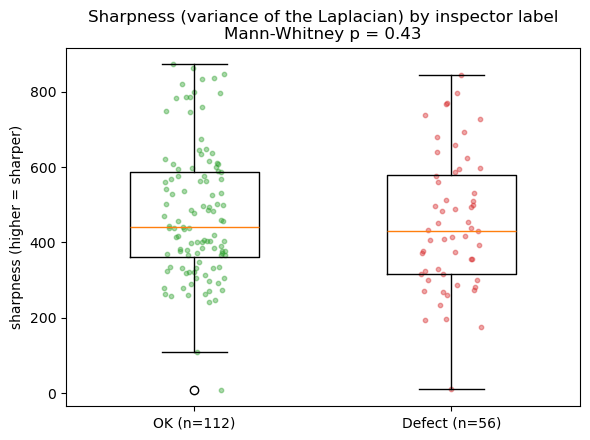

In [12]:
# B3
from scipy.stats import mannwhitneyu

ok = train.loc[train["inspector_label"] == 0, "sharpness"]
defect = train.loc[train["inspector_label"] == 1, "sharpness"]

summary_b3 = train.groupby("inspector_label")["sharpness"].agg(["count", "mean", "median", "std"]).round(2)
summary_b3.index = summary_b3.index.map({0: "OK (0)", 1: "Defect (1)"})
display(summary_b3)

p_mw = mannwhitneyu(ok, defect).pvalue
print(f"Mann-Whitney U test p-value: {p_mw:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.boxplot([ok, defect], widths=0.5)
ax.set_xticks([1, 2], [f"OK (n={len(ok)})", f"Defect (n={len(defect)})"])
rng = np.random.default_rng(0)
for i, values in enumerate([ok, defect], start=1):
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(values)), values, s=10, alpha=0.4,
               color="tab:green" if i == 1 else "tab:red")
ax.set_title(f"Sharpness (variance of the Laplacian) by inspector label\nMann-Whitney p = {p_mw:.2f}")
ax.set_ylabel("sharpness (higher = sharper)")
plt.tight_layout()
plt.show()

In [13]:
# C1
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def extract_extra_features(path):
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    edges = cv2.Canny(gray, 100, 200)

    # plate mask: Otsu threshold separates the bright plate from the dark background
    _, mask = cv2.threshold(cv2.GaussianBlur(gray, (5, 5), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, hierarchy = cv2.findContours(mask, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    plate = max(range(len(contours)), key=lambda i: cv2.contourArea(contours[i]))
    # dark shapes inside the plate (holes, screws, bars): contours whose parent is the plate
    n_shapes = sum(1 for i in range(len(contours)) if hierarchy[0][i][3] == plate)

    return {"brightness": float(gray.mean()),
            "contrast": float(gray.std()),
            "edge_percentage": float(np.count_nonzero(edges) / edges.size * 100),
            "n_shapes": n_shapes}

def add_extra_features(df):
    extra = df["file"].apply(lambda f: pd.Series(extract_extra_features(DATA_DIR / f)))
    extra["n_shapes"] = extra["n_shapes"].astype(int)
    return pd.concat([df.drop(columns=extra.columns, errors="ignore"), extra], axis=1)  # safe to re-run

train = add_extra_features(train)

# final features: distance from the normal number of shapes + share of edge pixels
FEATURES = ["shape_count_diff", "edge_percentage"]

def build_model():
    return make_pipeline(StandardScaler(), LogisticRegression())

,images,labeled OK (0),labeled defect (1),defect share %
dev,117,78,39,33.3
validation,51,34,17,33.3


expected number of shapes on an OK plate (mode of OK images in dev): 15


n_shapes,14,15,16,17,19
inspector_type,,,,,
edge_chip,0,0,10,0,1
missing_hole,5,0,0,0,0
none,3,70,5,0,0
scratch,0,4,2,2,0
stain,3,12,0,0,0


,features,cv_roc_auc_mean,cv_roc_auc_std
0,shape_count_diff + edges (chosen),0.809,0.083
1,all,0.788,0.112
2,shape_count_diff only,0.745,0.125
3,sharpness + noise (B2),0.529,0.176
4,"+ brightness, contrast, edges",0.474,0.131
5,"+ camera, exposure (metadata)",0.428,0.126


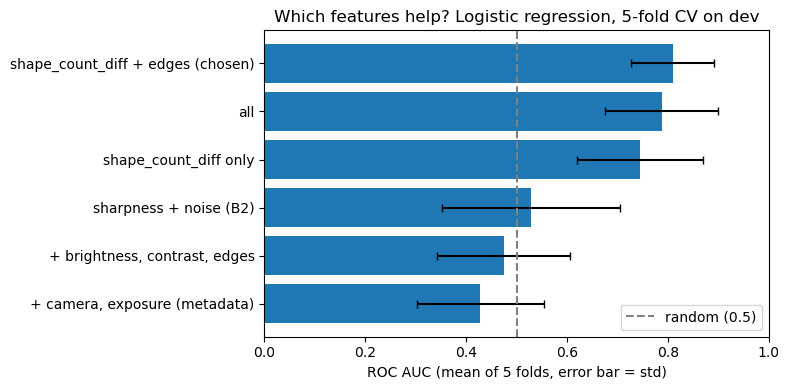

In [14]:
# C2
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

dev, val = train_test_split(train, test_size=0.3, stratify=train["inspector_label"], random_state=42)
dev, val = dev.copy(), val.copy()

# a normal part has a fixed number of shapes; learn it from the OK images in dev only
expected_shapes = int(dev.loc[dev["inspector_label"] == 0, "n_shapes"].mode()[0])
for df in (dev, val):
    df["shape_count_diff"] = (df["n_shapes"] - expected_shapes).abs()
    df["is_cam_b"] = (df["camera"] == "CAM-B").astype(int)
    df["is_low"] = (df["exposure_setting"] == "LOW").astype(int)

split_summary = pd.DataFrame({
    "images": [len(dev), len(val)],
    "labeled OK (0)": [(dev["inspector_label"] == 0).sum(), (val["inspector_label"] == 0).sum()],
    "labeled defect (1)": [(dev["inspector_label"] == 1).sum(), (val["inspector_label"] == 1).sum()],
    "defect share %": [round(dev["inspector_label"].mean() * 100, 1), round(val["inspector_label"].mean() * 100, 1)],
}, index=["dev", "validation"])
display(split_summary)
print("expected number of shapes on an OK plate (mode of OK images in dev):", expected_shapes)
display(pd.crosstab(dev["inspector_type"], dev["n_shapes"]))

feature_sets = {
    "sharpness + noise (B2)": ["sharpness", "noise_percentage"],
    "+ brightness, contrast, edges": ["sharpness", "noise_percentage", "brightness", "contrast", "edge_percentage"],
    "+ camera, exposure (metadata)": ["sharpness", "noise_percentage", "is_cam_b", "is_low"],
    "shape_count_diff only": ["shape_count_diff"],
    "shape_count_diff + edges (chosen)": FEATURES,
    "all": ["shape_count_diff", "sharpness", "noise_percentage", "brightness", "contrast", "edge_percentage", "is_cam_b", "is_low"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, cols in feature_sets.items():
    auc = cross_val_score(build_model(), dev[cols], dev["inspector_label"], cv=cv, scoring="roc_auc")
    rows.append({"features": name, "cv_roc_auc_mean": auc.mean().round(3), "cv_roc_auc_std": auc.std().round(3)})
cv_results = pd.DataFrame(rows).sort_values("cv_roc_auc_mean", ascending=False).reset_index(drop=True)
display(cv_results)

fig, ax = plt.subplots(figsize=(8, 4))
plot_df = cv_results.iloc[::-1]  # best at the top
ax.barh(plot_df["features"], plot_df["cv_roc_auc_mean"], xerr=plot_df["cv_roc_auc_std"], color="tab:blue", capsize=3)
ax.axvline(0.5, color="gray", ls="--", label="random (0.5)")
ax.set_xlim(0, 1)
ax.set_xlabel("ROC AUC (mean of 5 folds, error bar = std)")
ax.set_title("Which features help? Logistic regression, 5-fold CV on dev")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# fit the final model on dev only (validation stays unseen for Part D)
model = build_model().fit(dev[FEATURES], dev["inspector_label"])

# ---------------------------------------------------------------------------
# Conclusion (see the tables and the graph above):
# - The split was done before choosing features, so the choice uses dev only;
#   validation is kept for Part D, and test.csv is not used to evaluate or tune.
# - The most useful feature is shape_count_diff: how far the number of dark shapes on
#   the plate (holes, screws, bars) is from a normal part (the mode of the OK images in
#   dev). A missing hole lowers the count; an edge chip or a scratch can add a shape,
#   so the absolute difference is used.
# - shape_count_diff + edge_percentage gives the best AUC with only two features,
#   better than using all features.
# - Global features (sharpness, noise, brightness, contrast) and metadata (camera,
#   exposure) are close to random (AUC ~0.5), consistent with Parts A and B.
# - inspector_type was used only to inspect the data, never as a feature: it is the
#   label itself ("none" = OK) and would leak the answer into the model.
# ---------------------------------------------------------------------------

In [15]:
# C3
test = add_extra_features(test)
test["shape_count_diff"] = (test["n_shapes"] - expected_shapes).abs()   # same expected value, learned on dev

predictions = pd.DataFrame({
    "image_id": test["image_id"],
    "score": model.predict_proba(test[FEATURES])[:, 1].round(4),        # probability of class 1 (defect)
})
predictions["predicted_defect"] = (predictions["score"] >= 0.5).astype(int)
predictions = predictions[["image_id", "predicted_defect", "score"]]
predictions.to_csv("predictions.csv", index=False)

In [16]:
# D1
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score)

val_pred = model.predict(val[FEATURES])                  # threshold 0.5
val_score = model.predict_proba(val[FEATURES])[:, 1]
y_val = val["inspector_label"]

cm = confusion_matrix(y_val, val_pred)
cm_table = pd.DataFrame(cm,
                        index=["labeled OK (0)", "labeled defect (1)"],
                        columns=["predicted OK (0)", "predicted defect (1)"])
cm_table.loc["total"] = cm_table.sum()
cm_table["total"] = cm_table.sum(axis=1)
print(f"Confusion matrix – validation set (n={len(val)}), threshold 0.5")
display(cm_table)

tn, fp, fn, tp = cm.ravel()
metrics = pd.DataFrame({
    "value": [accuracy_score(y_val, val_pred), precision_score(y_val, val_pred),
              recall_score(y_val, val_pred), f1_score(y_val, val_pred), roc_auc_score(y_val, val_score)],
    "meaning": ["share of all images classified correctly",
                f"of the {tp + fp} images flagged as defect, share that were labeled defect",
                f"of the {tp + fn} images labeled defect, share the model caught",
                "harmonic mean of precision and recall",
                "ranking quality of the score (0.5 = random, 1 = perfect)"],
}, index=["accuracy", "precision", "recall", "F1", "ROC AUC"]).round(3)
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
display(metrics)

Confusion matrix – validation set (n=51), threshold 0.5


,predicted OK (0),predicted defect (1),total
labeled OK (0),32,2,34
labeled defect (1),8,9,17
total,40,11,51


TN=32  FP=2  FN=8  TP=9


,value,meaning
accuracy,0.804,share of all images classified correctly
precision,0.818,"of the 11 images flagged as defect, share that..."
recall,0.529,"of the 17 images labeled defect, share the mod..."
F1,0.643,harmonic mean of precision and recall
ROC AUC,0.729,"ranking quality of the score (0.5 = random, 1 ..."


inspector_label              1
inspector_type           stain
camera                   CAM-B
exposure_setting           LOW
n_shapes                    15
shape_count_diff             0
edge_percentage       4.616667
sharpness           197.671776
predicted                    0
score                    0.083
Name: IMG_0157, dtype: object
low-quality bound (edge_percentage): 4.63 | median edge_percentage in dev: 5.01 | median sharpness in dev: 453


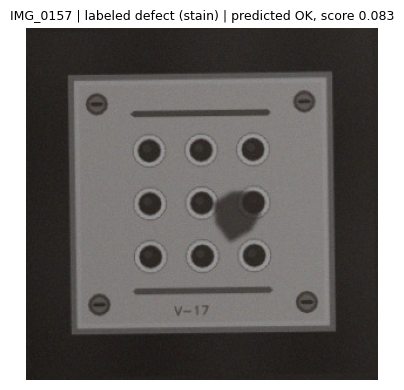

In [17]:
# D2
example_id = "IMG_0157"
row = val.assign(predicted=val_pred, score=val_score.round(3)).set_index("image_id").loc[example_id]
print(row[["inspector_label", "inspector_type", "camera", "exposure_setting", "n_shapes",
           "shape_count_diff", "edge_percentage", "sharpness", "predicted", "score"]])

# low-quality bound for edge_percentage, learned on dev (Tukey rule: Q1 - 1.5 * IQR)
q1, q3 = dev["edge_percentage"].quantile([0.25, 0.75])
low_edge_bound = q1 - 1.5 * (q3 - q1)
print(f"low-quality bound (edge_percentage): {low_edge_bound:.2f} | median edge_percentage in dev: {dev['edge_percentage'].median():.2f}"
      f" | median sharpness in dev: {dev['sharpness'].median():.0f}")

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(Image.open(DATA_DIR / row["file"]))
ax.set_title(f"{example_id} | labeled defect ({row['inspector_type']}) | predicted OK, score {row['score']}", fontsize=9)
ax.axis("off")
plt.tight_layout()
plt.show()

In [18]:
# Final checks – predictions.csv and image quality (supports D2 and E)
# sanity checks on the saved file
check = pd.read_csv("predictions.csv")
print("rows:", len(check), "| columns:", list(check.columns))
print("same image_ids as test.csv:", set(check["image_id"]) == set(test["image_id"]), "| duplicates:", check["image_id"].duplicated().sum())
print("predicted_defect values:", sorted(check["predicted_defect"].unique()), "| score range:", check["score"].min(), "-", check["score"].max())
print("predicted defect share in test:", round(check["predicted_defect"].mean() * 100, 1), "%")

# quality check: very blurry images have far fewer edges than normal ones (bound learned on dev, Tukey rule)
q1, q3 = dev["edge_percentage"].quantile([0.25, 0.75])
low_edge_bound = q1 - 1.5 * (q3 - q1)
print(f"\nlow-quality bound (edge_percentage): {low_edge_bound:.2f}"
      f" | dev images below it: {(dev['edge_percentage'] < low_edge_bound).sum()} of {len(dev)}"
      f" | test images below it: {(test['edge_percentage'] < low_edge_bound).sum()} of {len(test)}")
low_quality = test.loc[test["edge_percentage"] < low_edge_bound, ["image_id", "camera", "exposure_setting", "batch", "n_shapes", "edge_percentage"]]
display(low_quality.merge(check, on="image_id"))

rows: 72 | columns: ['image_id', 'predicted_defect', 'score']
same image_ids as test.csv: True | duplicates: 0
predicted_defect values: [0, 1] | score range: 0.0 - 0.8753
predicted defect share in test: 25.0 %

low-quality bound (edge_percentage): 4.63 | dev images below it: 4 of 117 | test images below it: 7 of 72


,image_id,camera,exposure_setting,batch,n_shapes,edge_percentage,predicted_defect,score
0,IMG_0109,CAM-B,AUTO,BATCH-B,17,0.691111,0,0.0016
1,IMG_0115,CAM-B,AUTO,BATCH-B,15,1.305556,0,0.0000
2,IMG_0184,CAM-B,LOW,BATCH-D,14,0.694444,0,0.0001
3,IMG_0194,CAM-B,LOW,BATCH-D,19,0.681111,0,0.2635
4,IMG_0197,CAM-B,NORMAL,BATCH-D,14,1.271111,0,0.0004
5,IMG_0216,CAM-B,LOW,BATCH-D,13,0.673333,0,0.0016
6,IMG_0227,CAM-B,NORMAL,BATCH-D,14,1.280000,0,0.0004


### D1 – Validation results

On the validation set (51 images, never used for training or for choosing features), the model flags 11 images as defective, and 9 of them were labeled defective (precision 0.82). It catches 9 of the 17 images labeled defective (recall 0.53). So when the model raises an alert it is usually right, but it misses about half of the defects. Accuracy is 0.80, F1 0.64 and ROC AUC 0.73.

### D2 – An image the model got wrong: IMG_0157

IMG_0157 is labeled defective (stain) but the model predicts OK, with a low score (0.08). There is a clear dark stain on the plate, but it touches one of the holes, so in the plate mask the stain and the hole merge into one dark shape. The shape count stays at the normal 15 (shape_count_diff = 0), so the main feature does not see the defect. In addition, the image is blurrier than most (sharpness 198 vs. a median of about 450, and edge_percentage right at the low-quality bound). Fewer edges lower the score even more, and the model saw very few blurry images in training. The same issue appears in the test set: 7 of 72 test images (all from CAM-B) are very blurry, and the model gives all of them a score close to 0, which should not be trusted.

As required, no test images were labeled manually, and the predictions were not set by image ID. No images were hand-picked for training either: the development/validation split is random (stratified by label, fixed `random_state=42`), so blurry images were not added to or removed from training on purpose.

### E – Summary and conclusions

**Key conclusions**

1. **Camera and exposure do not explain the defect labels.** The defect rate is similar for both cameras (31.6% vs. 35.6%), and within CAM-B, where LOW exposure exists, the correlation between low exposure and the defect label is close to zero (Pearson r = 0.055, Fisher p = 0.80).
2. **Global image-quality features do not separate OK from defective parts.** Sharpness, noise, brightness and contrast are almost the same in both groups (cross-validation AUC close to 0.5). The defects are small and local, so features computed over the whole image barely change.
3. **A simple structural feature works much better.** A normal part has 15 dark shapes on the plate (9 holes, 4 screws, 2 bars). Counting them with OpenCV contours catches missing holes (14 shapes) and most edge chips (16). A logistic regression on this shape-count difference plus the share of edge pixels reaches a cross-validation AUC of about 0.81 on the development set.
4. **On the validation set the model is precise but misses defects:** precision 0.82, recall 0.53 (9 of 17 defects caught, 2 false alarms). All 8 missed defects are stains or scratches that do not change the shape count, so the model is weak exactly on that type of defect.
5. **Image quality is a real limitation.** 7 of 72 test images (9.7%, all from CAM-B) are very blurry, compared with 4 of 117 in the development set (3.4%). The model gives all of them a score close to 0. This score should not be trusted, and these images would need to be photographed again rather than auto-approved. This also suggests that part of the problem described in the background may come from photography conditions on CAM-B, not only from the parts themselves.
6. **The labels are not perfect.** For example, some images labeled "stain" show no clear stain, and a few images labeled OK have an unusual shape count. The metrics above measure agreement with the inspector, not true accuracy.

**Use of AI**

I used Claude (Opus 5.5) throughout the task. AI is a good executor: it knows a lot and writes working code quickly (especially the newer models: Opus 5.5 / Fable 5.1 / Fable 5.2 / Gemini 4 / ChatGPT Astra 6). But it needs a clear lead – someone who knows the goal and can direct it. Its first suggestions were usually right, but not always:
- It recommended installing `requirements_suggested.txt`, which upgraded NumPy to 2.x and broke pandas in my Anaconda environment. I rolled back to NumPy 1.x with a compatible OpenCV version.
- It sometimes thinks ahead and mixes up the order of the task: it put the train/validation split inside C1 because feature selection needed it. I kept the structure strict to the instructions: build the model in C1, then show how and why in C2.
- It placed a finding and an insight from two different graphs in A3; the task asks for both from the same graph, so I changed the graph.
- When I suggested that IMG_0157 was missed only because of blur, checking the image showed the main reason was different: the stain touches a hole and merges with it into one shape.

To verify the work, I ran every cell, compared the outputs with the values I expected, checked the model on a validation set it never saw, and checked `predictions.csv` itself (72 rows, same image IDs as `test.csv`, no duplicates, values 0/1, scores between 0 and 1).